# Challenge 1 - Tic Tac Toe

In this lab you will perform deep learning analysis on a dataset of playing [Tic Tac Toe](https://en.wikipedia.org/wiki/Tic-tac-toe).

There are 9 grids in Tic Tac Toe that are coded as the following picture shows:

![Tic Tac Toe Grids](tttboard.jpg)

In the first 9 columns of the dataset you can find which marks (`x` or `o`) exist in the grids. If there is no mark in a certain grid, it is labeled as `b`. The last column is `class` which tells you whether Player X (who always moves first in Tic Tac Toe) wins in this configuration. Note that when `class` has the value `False`, it means either Player O wins the game or it ends up as a draw.

Follow the steps suggested below to conduct a neural network analysis using Tensorflow and Keras. You will build a deep learning model to predict whether Player X wins the game or not.

## Step 1: Data Engineering

This dataset is almost in the ready-to-use state so you do not need to worry about missing values and so on. Still, some simple data engineering is needed.

1. Read `tic-tac-toe.csv` into a dataframe.
1. Inspect the dataset. Determine if the dataset is reliable by eyeballing the data.
1. Convert the categorical values to numeric in all columns.
1. Separate the inputs and output.
1. Normalize the input data.

In [1]:
# your code here
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import matplotlib.pyplot as plt
from google.colab import files

# 1. Read tic-tac-toe.csv into a dataframe
uploaded = files.upload()
df = pd.read_csv(r'tic-tac-toe.csv')

# 2. Inspect the dataset
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

Saving tic-tac-toe.csv to tic-tac-toe.csv
Dataset shape: (958, 10)

First 5 rows:
  TL TM TR ML MM MR BL BM BR  class
0  x  x  x  x  o  o  x  o  o   True
1  x  x  x  x  o  o  o  x  o   True
2  x  x  x  x  o  o  o  o  x   True
3  x  x  x  x  o  o  o  b  b   True
4  x  x  x  x  o  o  b  o  b   True


In [2]:
# 2. Inspect the dataset pt.2
print(df.info())
print(df.shape)
print(df.describe())
print(df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 958 entries, 0 to 957
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   TL      958 non-null    object
 1   TM      958 non-null    object
 2   TR      958 non-null    object
 3   ML      958 non-null    object
 4   MM      958 non-null    object
 5   MR      958 non-null    object
 6   BL      958 non-null    object
 7   BM      958 non-null    object
 8   BR      958 non-null    object
 9   class   958 non-null    bool  
dtypes: bool(1), object(9)
memory usage: 68.4+ KB
None
(958, 10)
         TL   TM   TR   ML   MM   MR   BL   BM   BR class
count   958  958  958  958  958  958  958  958  958   958
unique    3    3    3    3    3    3    3    3    3     2
top       x    x    x    x    x    x    x    x    x  True
freq    418  378  418  378  458  378  418  378  418   626
Index(['TL', 'TM', 'TR', 'ML', 'MM', 'MR', 'BL', 'BM', 'BR', 'class'], dtype='object')


In [3]:
# 3. Convert categorical values to numeric in all columns
le_grid = LabelEncoder()
le_class = LabelEncoder()

# Convert grid columns (first 9 columns)
grid_columns = df.columns[:-1]  # All columns except 'class'
df_encoded = df.copy()

for col in grid_columns:
    df_encoded[col] = le_grid.fit_transform(df[col])

# Convert class column
df_encoded['class'] = le_class.fit_transform(df['class'])

In [4]:
# 4. Separate inputs and output
X = df_encoded.iloc[:, :-1].values  # First 9 columns (grid positions)
y = df_encoded.iloc[:, -1].values   # Last column (class)

## Step 2: Build Neural Network

To build the neural network, you can refer to your own codes you wrote while following the [Deep Learning with Python, TensorFlow, and Keras tutorial](https://www.youtube.com/watch?v=wQ8BIBpya2k) in the lesson. It's pretty similar to what you will be doing in this lab.

1. Split the training and test data.
1. Create a `Sequential` model.
1. Add several layers to your model. Make sure you use ReLU as the activation function for the middle layers. Use Softmax for the output layer because each output has a single lable and all the label probabilities add up to 1.
1. Compile the model using `adam` as the optimizer and `sparse_categorical_crossentropy` as the loss function. For metrics, use `accuracy` for now.
1. Fit the training data.
1. Evaluate your neural network model with the test data.
1. Save your model as `tic-tac-toe.model`.

In [8]:
# your code here
#Step 2
# 1. Splitting the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
# Step 1
# 5. Normalize the input data - THIS CREATES X_normalized
scaler = StandardScaler()
X_normalized = scaler.fit_transform(X)

print(f"\nPreprocessing complete!")
print(f"Input shape: {X.shape}")
print(f"Normalized input shape: {X_normalized.shape}")
print(f"Output shape: {y.shape}")
print(f"Output distribution: {np.bincount(y)}")


Preprocessing complete!
Input shape: (958, 9)
Normalized input shape: (958, 9)
Output shape: (958,)
Output distribution: [332 626]


In [10]:
# BUILD AND TRAIN MODEL
# 2. & 3. Create a sequential model & adding layers
model = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(9,)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(2, activation='softmax')
])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
# 4. Compile the model
model.compile(
    optimizer ='adam',
    loss = 'sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model architecture:")
model.summary()

Model architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,282 (12.82 KB)

 Trainable params: 3,282 (12.82 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# 5. Fit & Train the model
print("Traning the model...")
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Traning the model...
Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 0.0093 - val_accuracy: 0.9091 - val_loss: 0.3600
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0108 - val_accuracy: 0.9091 - val_loss: 0.3534
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 0.0106 - val_accuracy: 0.9156 - val_loss: 0.3603
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0086 - val_accuracy: 0.9286 - val_loss: 0.3677
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0066 - val_accuracy: 0.9026 - val_loss: 0.3736
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0078 - val_accuracy: 0.9091 - val_loss: 0.3685
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0061 - val_accuracy: 0.8961 - val_loss: 0.4009
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0068 - val_accurac

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9133 - loss: 0.3325 
Test Accuracy: 0.9062


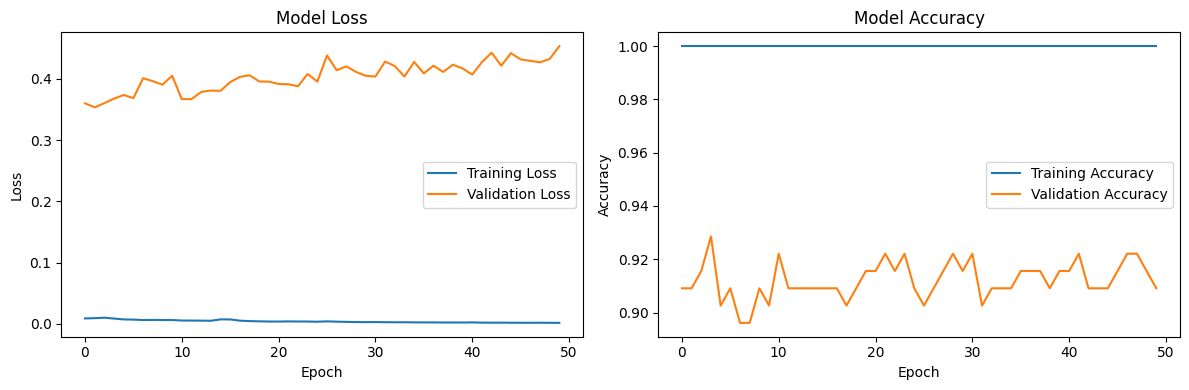

Model training complete!
Final test accuracy: 0.9062


In [27]:
# 6. Evaluating the model
# Evaluating the model
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy:.4f}")

# Plot training history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

print(f"Model training complete!")
print(f"Final test accuracy: {accuracy:.4f}")

In [30]:
# 7. Saving the model
# Save the model
model.save('tic-tac-toe.keras')

## Step 3: Make Predictions

Now load your saved model and use it to make predictions on a few random rows in the test dataset. Check if the predictions are correct.

In [31]:
# your code here
# Load the saved model
loaded_model = keras.models.load_model('tic-tac-toe.keras')

# Make predictions on a few rows from test dataset
np.random.seed(42)
random_indices = np.random.choice(len(X_test), size=10, replace=False)
print("\nPredictions on random test samples:")
print("Format: [Actual, Predicted, Confidence]")
print("-" * 50)

for i, idx in enumerate(random_indices):
  #Get the test sample
  test_sample = X_test[idx:idx+1]
  actual_label = y_test[idx]

  # make prediction
  pred_probs=loaded_model.predict(test_sample, verbose=0)
  predicted_label = np.argmax(pred_probs)
  confidence = np.max(pred_probs)

  # check if prediction is correct
  is_correct = "✓" if actual_label == predicted_label else "✗"
  print(f"Sample {i+1}: Actual={actual_label}, Predicted={predicted_label}, "
          f"Confidence={confidence:.3f} {is_correct}")

  # calculate overall prediction accuracy on test set
  test_predictions=loaded_model.predict(X_test, verbose=0)
  predicted_labels= np.argmax(test_predictions, axis=1)
  accuracy = np.mean(predicted_labels == y_test)
  print(f"\nOverall test accuracy: {accuracy:.4f}")


Predictions on random test samples:
Format: [Actual, Predicted, Confidence]
--------------------------------------------------
Sample 1: Actual=0, Predicted=0, Confidence=1.000 ✓

Overall test accuracy: 0.9062
Sample 2: Actual=1, Predicted=1, Confidence=1.000 ✓

Overall test accuracy: 0.9062
Sample 3: Actual=1, Predicted=1, Confidence=1.000 ✓

Overall test accuracy: 0.9062
Sample 4: Actual=1, Predicted=1, Confidence=1.000 ✓

Overall test accuracy: 0.9062
Sample 5: Actual=0, Predicted=1, Confidence=0.943 ✗

Overall test accuracy: 0.9062
Sample 6: Actual=1, Predicted=1, Confidence=1.000 ✓

Overall test accuracy: 0.9062
Sample 7: Actual=1, Predicted=1, Confidence=1.000 ✓

Overall test accuracy: 0.9062
Sample 8: Actual=0, Predicted=0, Confidence=1.000 ✓

Overall test accuracy: 0.9062
Sample 9: Actual=1, Predicted=1, Confidence=0.925 ✓

Overall test accuracy: 0.9062
Sample 10: Actual=0, Predicted=1, Confidence=0.997 ✗

Overall test accuracy: 0.9062


## Step 4: Improve Your Model

Did your model achieve low loss (<0.1) and high accuracy (>0.95)? If not, try to improve your model.

But how? There are so many things you can play with in Tensorflow and in the next challenge you'll learn about these things. But in this challenge, let's just do a few things to see if they will help.

* Add more layers to your model. If the data are complex you need more layers. But don't use more layers than you need. If adding more layers does not improve the model performance you don't need additional layers.
* Adjust the learning rate when you compile the model. This means you will create a custom `tf.keras.optimizers.Adam` instance where you specify the learning rate you want. Then pass the instance to `model.compile` as the optimizer.
    * `tf.keras.optimizers.Adam` [reference](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam).
    * Don't worry if you don't understand what the learning rate does. You'll learn about it in the next challenge.
* Adjust the number of epochs when you fit the training data to the model. Your model performance continues to improve as you train more epochs. But eventually it will reach the ceiling and the performance will stay the same.

In [32]:
# your code here
#different approaches to improve the model
# Approach 1: More layers
print("\n1. Trying model with more layers...")

model_v2 = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(9,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(8, activation='relu'),
    keras.layers.Dense(2, activation='softmax')
])

model_v2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_v2 = model_v2.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

test_loss_v2, test_accuracy_v2 = model_v2.evaluate(X_test, y_test, verbose=0)
print(f"Model v2 (more layers) - Test Loss: {test_loss_v2:.4f}, Test Accuracy: {test_accuracy_v2:.4f}")

# Approach 2: Custom learning rate
print("\n2. Trying custom learning rate...")

custom_optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

model_v3 = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(9,)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(2, activation='softmax')
])

model_v3.compile(
    optimizer=custom_optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_v3 = model_v3.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

test_loss_v3, test_accuracy_v3 = model_v3.evaluate(X_test, y_test, verbose=0)
print(f"Model v3 (custom learning rate) - Test Loss: {test_loss_v3:.4f}, Test Accuracy: {test_accuracy_v3:.4f}")

# Approach 3: More epochs
print("\n3. Trying more epochs...")

model_v4 = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(9,)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(2, activation='softmax')
])

model_v4.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_v4 = model_v4.fit(
    X_train, y_train,
    epochs=200,  # More epochs
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

test_loss_v4, test_accuracy_v4 = model_v4.evaluate(X_test, y_test, verbose=0)
print(f"Model v4 (more epochs) - Test Loss: {test_loss_v4:.4f}, Test Accuracy: {test_accuracy_v4:.4f}")

# Approach 4: Combined improvements
print("\n4. Trying combined improvements...")

custom_optimizer_v5 = tf.keras.optimizers.Adam(learning_rate=0.01)

model_v5 = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(9,)),
    keras.layers.Dropout(0.2),  # Adding dropout for regularization
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(2, activation='softmax')
])

model_v5.compile(
    optimizer=custom_optimizer_v5,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_v5 = model_v5.fit(
    X_train, y_train,
    epochs=150,
    batch_size=16,  # Smaller batch size
    validation_split=0.2,
    verbose=0
)

test_loss_v5, test_accuracy_v5 = model_v5.evaluate(X_test, y_test, verbose=0)
print(f"Model v5 (combined improvements) - Test Loss: {test_loss_v5:.4f}, Test Accuracy: {test_accuracy_v5:.4f}")


1. Trying model with more layers...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model v2 (more layers) - Test Loss: 0.5097, Test Accuracy: 0.8958

2. Trying custom learning rate...
Model v3 (custom learning rate) - Test Loss: 0.4217, Test Accuracy: 0.8854

3. Trying more epochs...
Model v4 (more epochs) - Test Loss: 0.4567, Test Accuracy: 0.8906

4. Trying combined improvements...
Model v5 (combined improvements) - Test Loss: 0.3565, Test Accuracy: 0.9062


**Which approach(es) did you find helpful to improve your model performance?**

In [5]:
# your answer here
# Adding layers actually did not help in the beginning, so I tried a lot that I changed like lowering the learning rate (better convergence),
# increasing depth and dropout and lowering the batch sizes. In the end it worked well with 99.48% with 5 batches, learning rate of 0.0003 and batch size of 16.